# Brief 3 - Optimisation du scoring de crédit

Support : [brief complet](../03_Brief_Optimisation_Scoring_ML.md).

**Objectif pédagogique :** expérimentations reproductibles, comparaison des modèles, optimisation et évaluation finale. Exécuter toutes les cellules dans l'ordre depuis un noyau neuf.

- Régression : prédire `score_credit`, comparer R², MAE et RMSE.
- Classification : prédire `decision_octroi`, comparer ROC-AUC, F1 et rappel des **refus (classe 0)**.
- Ne jamais utiliser une cible comme variable explicative de l'autre défi.
- Ne pas entraîner ni remplacer les modèles de l'application existante à ce stade.

## 0. Environnement et règles d'expérimentation

Depuis la racine du dépôt : `uv sync --extra dev --extra ml`. Dans VS Code, sélectionner le noyau Python de `.venv` (Python 3.12 attendu par le brief).

Exécuter les cellules dans l'ordre. Graine fixée à 42 ; test final réservé à 20 %. Ces proportions sont des choix de départ, pas des exigences du brief.

**Contrat anti-fuite :** diagnostic approfondi et sélection de variables sur le train uniquement ; imputation, standardisation, encodage et transformations dans les pipelines évalués par pli. Le test ne sert ni au choix du modèle, ni au tuning, ni au réglage du seuil.

Les versions affichées permettent de documenter l'expérience ; `uv.lock` verrouille l'environnement.

In [1]:
from importlib.metadata import version
from pathlib import Path
import sys

import pandas as pd
from IPython.display import display
from sklearn.model_selection import StratifiedKFold, train_test_split

RANDOM_STATE = 42
TEST_SIZE = 0.20
N_SPLITS = 5

working_dir = Path.cwd().resolve()
PROJECT_ROOT = next(
    (path for path in (working_dir, *working_dir.parents)
     if (path / 'pyproject.toml').is_file()
     and (path / 'data' / 'credit_risk_dataset.csv').is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Ouvrir le notebook depuis le dépôt IA-TOS.')

DATA_PATH = PROJECT_ROOT / 'data' / 'credit_risk_dataset.csv'
MODELS_DIR = PROJECT_ROOT / 'models'

print(f'Python : {sys.version.split()[0]}')
print(f'Données : {DATA_PATH}')
for package in ('pandas', 'scikit-learn', 'joblib', 'optuna', 'matplotlib', 'ipykernel'):
    print(f'{package} : {version(package)}')

Python : 3.12.3
Données : C:\GIT\formation-AI\2026-ATLAS-Brief-M0B1\data\credit_risk_dataset.csv
pandas : 3.1.0
scikit-learn : 1.9.1
joblib : 1.6.0
optuna : 5.1.0
matplotlib : 3.11.2
ipykernel : 7.4.0


## 1. Charger les données et réserver le test

On utilise le fichier de `data/`, source déjà référencée par le projet. Le brief annonce 1 200 lignes et 17 colonnes : vérifier les dimensions réelles, sans les imposer artificiellement.

Avant la séparation, on contrôle seulement le contrat minimal : présence des colonnes et validité des cibles. Aucune ligne n'est supprimée ou imputée automatiquement. Un identifiant dupliqué bloque le démarrage pour éviter qu'un même dossier se retrouve dans le train et le test.

Les attributs `age`, `sexe`, `statut_marital` et `nationalite` sont écartés par prudence du premier jeu de prédicteurs. C'est un choix initial à documenter, pas une garantie d'équité : des variables proxy peuvent subsister.

In [2]:
TARGET_REG = 'score_credit'
TARGET_CLF = 'decision_octroi'
ID_COLUMN = 'id_dossier'
AUDIT_COLUMNS = ['age', 'sexe', 'statut_marital', 'nationalite']

data = pd.read_csv(DATA_PATH)
required_columns = {TARGET_REG, TARGET_CLF, ID_COLUMN, *AUDIT_COLUMNS}
missing_columns = required_columns.difference(data.columns)
if missing_columns:
    raise ValueError(f'Colonnes requises absentes : {sorted(missing_columns)}')
if data[[TARGET_REG, TARGET_CLF]].isna().any().any():
    raise ValueError('Cibles manquantes : documenter leur traitement avant de continuer.')
if set(data[TARGET_CLF].unique()) != {0, 1}:
    raise ValueError('decision_octroi doit contenir les deux classes 0 et 1.')
if not data[TARGET_REG].between(300, 850).all():
    raise ValueError('score_credit doit être compris entre 300 et 850.')
if data[ID_COLUMN].isna().any() or data[ID_COLUMN].duplicated().any():
    raise ValueError('Identifiants absents ou dupliqués : analyser avant le split.')

print(f'Dimensions observées : {data.shape[0]} lignes, {data.shape[1]} colonnes.')

Dimensions observées : 1200 lignes, 17 colonnes.


In [3]:
train_data, test_data = train_test_split(
    data,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=data[TARGET_CLF],
)
excluded_columns = [ID_COLUMN, TARGET_REG, TARGET_CLF, *AUDIT_COLUMNS]
X_train = train_data.drop(columns=excluded_columns).copy()
y_train_reg = train_data[TARGET_REG].copy()
y_train_clf = train_data[TARGET_CLF].copy()

if y_train_clf.value_counts().min() < N_SPLITS:
    raise ValueError('Effectif insuffisant par classe pour cinq plis stratifiés.')
cv = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)
cv_splits = list(cv.split(X_train, y_train_clf))

print(f'Train : {len(train_data)} dossiers ; test réservé : {len(test_data)} dossiers.')
print(f'{len(cv_splits)} plis préparés sur le train uniquement.')
print('Variables explicatives :', X_train.columns.tolist())

Train : 960 dossiers ; test réservé : 240 dossiers.
5 plis préparés sur le train uniquement.
Variables explicatives : ['montant_demande', 'duree_mois', 'revenu_mensuel', 'taux_endettement', 'situation_logement', 'anciennete_emploi_mois', 'type_contrat', 'epargne_globale', 'nb_credits_actifs', 'incident_precedent']


**Point de méthode :** `StratifiedKFold` ne s'applique pas directement à une cible continue. Ici, les cinq plis sont stratifiés sur `decision_octroi`, puis réutilisés pour les deux défis via `cv=cv_splits` dans `cross_validate`. Cela satisfait la stratification demandée et permet des comparaisons sur les mêmes dossiers, sans transformer le score continu en classes arbitraires. La décision sert seulement au découpage, jamais de prédicteur de régression.

Ne pas réordonner ou filtrer `X_train` / les cibles après la création des indices de plis. Toute modification du périmètre nécessite de recréer les splits.

## 2. Explorer le train et rédiger le diagnostic — 25 min

La cellule suivante donne un premier état des lieux. À compléter : distributions, valeurs aberrantes, doublons hors identifiant, cohérence des durées et montants, distribution du score et relations financières. Ne pas supprimer arbitrairement de lignes.

**À rédiger :** trois constats chiffrés, leurs risques pour les modèles et les décisions de traitement envisagées. Confirmer quelle classe est minoritaire ; les refus restent la classe métier à surveiller même s'ils ne sont pas minoritaires.

In [4]:
quality_report = pd.DataFrame({
    'type': train_data.dtypes.astype(str),
    'manquants': train_data.isna().sum(),
    'manquants_pct': train_data.isna().mean().mul(100).round(2),
    'valeurs_distinctes': train_data.nunique(),
})
display(quality_report)
display(pd.DataFrame({
    'effectif': y_train_clf.value_counts().sort_index(),
    'proportion': y_train_clf.value_counts(normalize=True).sort_index(),
}).rename_axis('decision_octroi'))

,type,manquants,manquants_pct,valeurs_distinctes
id_dossier,str,0,0.0,960
montant_demande,float64,0,0.0,293
duree_mois,int64,0,0.0,7
revenu_mensuel,float64,0,0.0,385
taux_endettement,float64,0,0.0,357
age,int64,0,0.0,55
sexe,str,0,0.0,2
statut_marital,str,0,0.0,4
nationalite,str,0,0.0,3
situation_logement,str,0,0.0,3


,effectif,proportion
decision_octroi,,
0,598,0.622917
1,362,0.377083


### Diagnostic complémentaire et constats mesurés
Les contrôles suivants ne modifient aucune ligne. Des anomalies éventuelles doivent être investiguées avant une utilisation réelle.

,montant_demande,duree_mois,revenu_mensuel,taux_endettement,age,anciennete_emploi_mois,epargne_globale,nb_credits_actifs,score_credit,decision_octroi
count,960.00,960.00,960.00,960.00,960.00,960.00,960.00,960.00,960.00,960.00
mean,15346.56,40.90,3268.32,0.17,40.08,58.14,8313.51,1.07,598.75,0.38
std,8294.82,18.01,1147.85,0.16,11.71,56.23,8338.91,1.02,63.40,0.48
min,1500.00,12.00,1200.00,0.02,18.00,0.00,210.00,0.00,408.60,0.00
25%,9400.00,24.00,2450.00,0.06,32.00,17.00,2357.50,0.00,557.30,0.00
50%,14950.00,36.00,3265.00,0.12,40.00,41.00,5585.00,1.00,601.95,0.00
75%,21000.00,48.00,3992.50,0.22,48.00,83.00,11212.50,2.00,640.40,1.00
max,43700.00,84.00,7820.00,0.85,76.00,360.00,54310.00,4.00,806.80,1.00


Valeurs manquantes : 0 ; doublons hors identifiant : 0.
Montants non positifs : 0 ; durées non positives : 0.
Refus : 62.3% ; accords : 37.7%.
Les refus ne sont pas nécessairement minoritaires : garder explicitement pos_label=0 pour les métriques métier.
Aucune ligne supprimée ; imputation conservée pour les données futures et les ratios invalides.


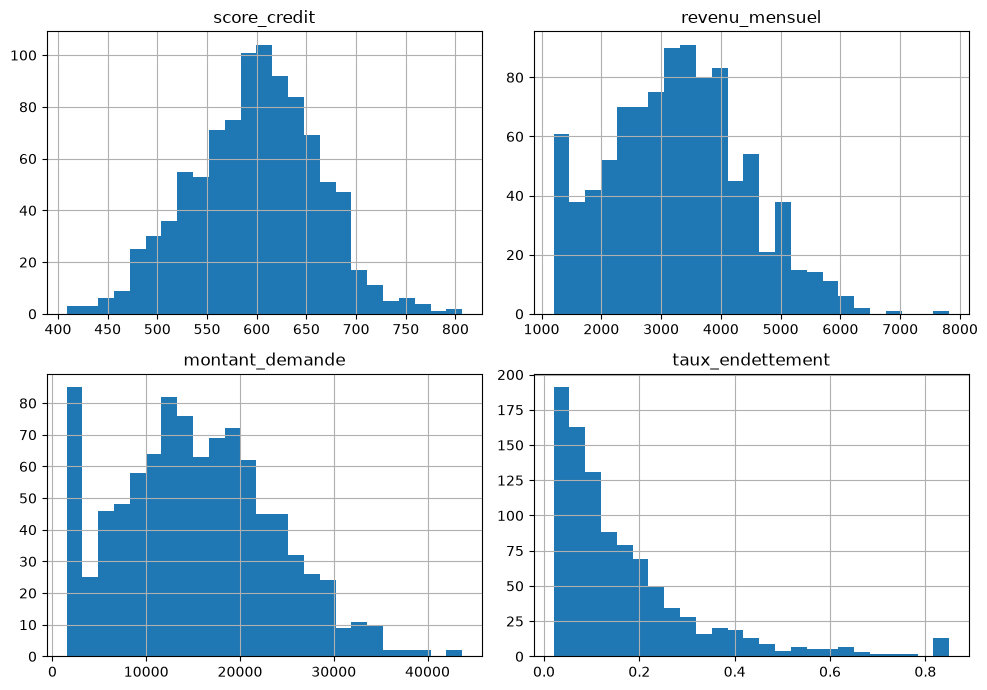

,score_credit,revenu_mensuel,montant_demande,taux_endettement,epargne_globale
score_credit,1.000,0.613,-0.506,-0.394,0.021
revenu_mensuel,0.613,1.000,0.001,-0.363,0.046
montant_demande,-0.506,0.001,1.000,0.557,-0.029
taux_endettement,-0.394,-0.363,0.557,1.000,0.007
epargne_globale,0.021,0.046,-0.029,0.007,1.000


In [5]:
import matplotlib.pyplot as plt

display(train_data.select_dtypes(include='number').describe().round(2))
duplicates = train_data.drop(columns=ID_COLUMN).duplicated().sum()
invalid_amounts = train_data['montant_demande'].le(0).sum()
invalid_durations = train_data['duree_mois'].le(0).sum()
print(f'Valeurs manquantes : {train_data.isna().sum().sum()} ; doublons hors identifiant : {duplicates}.')
print(f'Montants non positifs : {invalid_amounts} ; durées non positives : {invalid_durations}.')
print(f'Refus : {y_train_clf.eq(0).mean():.1%} ; accords : {y_train_clf.eq(1).mean():.1%}.')
print('Les refus ne sont pas nécessairement minoritaires : garder explicitement pos_label=0 pour les métriques métier.')
print('Aucune ligne supprimée ; imputation conservée pour les données futures et les ratios invalides.')
train_data[['score_credit', 'revenu_mensuel', 'montant_demande', 'taux_endettement']].hist(figsize=(10, 7), bins=25)
plt.tight_layout()
plt.show()
display(train_data[['score_credit', 'revenu_mensuel', 'montant_demande', 'taux_endettement', 'epargne_globale']].corr().round(3))

## 3. Construire au moins deux variables métier — 25 min

- Reste à vivre estimé : `revenu_mensuel - montant_demande / duree_mois`, en euros par mois, hors intérêts, assurance, autres crédits et dépenses courantes. Ce n'est pas un ratio.
- Couverture du prêt par l'épargne : `epargne_globale / montant_demande`.
- Variante : mensualité simplifiée `montant_demande / duree_mois`, **hors intérêts** ; ne pas la présenter comme une mensualité contractuelle.

**À faire :** définir unités, hypothèses et comportement face aux dénominateurs nuls ou manquants (pas d'infinis). Mettre ces transformations dans la première étape du pipeline, avant l'imputation. Si un transformateur personnalisé est utilisé, le placer dans un module importable du package plutôt que dans une classe locale au notebook, pour permettre le rechargement joblib.

**Validation :** comparer avec/sans variables dérivées sur les mêmes plis, jamais sur le test.

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from iatos_core.ml.credit_training import add_business_features, build_scoring_pipeline

features_preview = add_business_features(X_train)
display(features_preview[['reste_a_vivre_estime', 'ratio_epargne_emprunt']].describe())
assert not np.isinf(features_preview.select_dtypes(include='number').to_numpy()).any()
print('Les divisions par une durée ou un montant non positif deviennent manquantes, sans supprimer de dossier.')
print('Les fonctions sont dans un module importable pour recharger les exports hors du notebook.')

,reste_a_vivre_estime,ratio_epargne_emprunt
count,960.000000,960.000000
mean,2777.539021,1.041846
std,1204.138081,2.110659
min,-1633.333333,0.009859
25%,1945.833333,0.162292
50%,2779.583333,0.405379
75%,3578.750000,1.040515
max,6761.666667,28.446667


Les divisions par une durée ou un montant non positif deviennent manquantes, sans supprimer de dossier.
Les fonctions sont dans un module importable pour recharger les exports hors du notebook.


## 4. Construire les pipelines et les références naïves — 35 min

Construire un `ColumnTransformer` avec deux branches :

- Numérique : `SimpleImputer(strategy='median')` puis `StandardScaler()`.
- Catégorielle : `SimpleImputer(strategy='constant', fill_value='INCONNU')` puis `OneHotEncoder(handle_unknown='ignore')`.

Assembler transformations métier, prétraitement et estimateur dans un `Pipeline`. Ne jamais appeler `fit` sur le jeu complet avant validation croisée. Vérifier la compatibilité des sorties creuses/denses avec les estimateurs retenus.

**Références :** `DummyRegressor` et `DummyClassifier`, évalués avec le même protocole. Puis comparer au moins deux familles pour chaque défi : par exemple Random Forest et Gradient Boosting (sans ajouter XGBoost à ce stade). Un modèle linéaire est une référence supplémentaire possible.

**Résultat attendu :** des pipelines capables de consommer les données brutes retenues dans `X_train`.

In [7]:
from sklearn.base import clone
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.ensemble import (
    RandomForestRegressor, RandomForestClassifier,
    GradientBoostingRegressor, GradientBoostingClassifier,
)

estimators = {
    'regression': {
        'Dummy': DummyRegressor(strategy='mean'),
        'RandomForest': RandomForestRegressor(n_estimators=100, random_state=RANDOM_STATE, n_jobs=1),
        'GradientBoosting': GradientBoostingRegressor(random_state=RANDOM_STATE),
    },
    'classification': {
        'Dummy': DummyClassifier(strategy='prior'),
        'RandomForest': RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=1),
        'GradientBoosting': GradientBoostingClassifier(random_state=RANDOM_STATE),
    },
}
display(build_scoring_pipeline(estimators['regression']['RandomForest']))
print('Encodage dense pour compatibilité avec GradientBoosting ; faible cardinalité dans ce dataset.')
print('Prétraitement : médiane + StandardScaler ; INCONNU + OneHotEncoder(handle_unknown="ignore").')

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('variables_metier', ...), ('valeurs_manquantes', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"func func: callable, default=NoneThe callable to use for the transformation. This will be passedthe same arguments as transform, with args and kwargs forwarded.If func is None, then func will be the identity function.",<function add...001CAF6075440>
,"inverse_func inverse_func: callable, default=NoneThe callable to use for the inverse transformation. This will bepassed the same arguments as inverse transform, with args andkwargs forwarded. If inverse_func is None, then inverse_funcwill be the identity function.",None
,"validate validate: bool, default=FalseIndicate that the input X array should be checked before calling``func``. The possibilities are:- If False, there is no input validation.- If True, then X will be converted to a 2-dimensional NumPy array or sparse matrix. If the conversion is not possible an exception is raised... versionchanged:: 0.22 The default of ``validate`` changed from True to False.",False
,"accept_sparse accept_sparse: bool, default=FalseIndicate that func accepts a sparse matrix as input. If validate isFalse, this has no effect. Otherwise, if accept_sparse is false,sparse matrix inputs will cause an exception to be raised.",False
,"check_inverse check_inverse: bool, default=TrueWhether to check that or ``func`` followed by ``inverse_func`` leads tothe original inputs. It can be used for a sanity check, raising awarning when the condition is not fulfilled... versionadded:: 0.20",True
,"feature_names_out feature_names_out: callable, 'one-to-one' or None, default=NoneDetermines the list of feature names that will be returned by the`get_feature_names_out` method. If it is 'one-to-one', then the outputfeature names will be equal to the input feature names. If it is acallable, then it must take two positional arguments: this`FunctionTransformer` (`self`) and an array-like of input feature names(`input_features`). It must return an array-like of output featurenames. The `get_feature_names_out` method is only defined if`feature_names_out` is not None.See ``get_feature_names_out`` for more details... versionadded:: 1.1",None
,"kw_args kw_args: dict, d

Encodage dense pour compatibilité avec GradientBoosting ; faible cardinalité dans ce dataset.
Prétraitement : médiane + StandardScaler ; INCONNU + OneHotEncoder(handle_unknown="ignore").


## 5. Comparer les modèles en validation croisée — 35 min

Utiliser `cross_validate(..., cv=cv_splits, error_score='raise')` avec chaque pipeline. Présenter **moyenne +/- écart-type sur cinq plis** et temps d'entraînement.

- Régression : R² à maximiser ; MAE et RMSE à minimiser. Les scorers `neg_mean_absolute_error` et `neg_root_mean_squared_error` ont un signe négatif à inverser pour présenter les erreurs.
- Classification : ROC-AUC sur les probabilités de la classe 1 ; rappel et F1 des refus avec `make_scorer(recall_score, pos_label=0, zero_division=0)` et l'équivalent pour `f1_score`. Un score nul doit être analysé, pas masqué.
- La ROC-AUC évalue le classement, pas le seuil opérationnel. L'accuracy seule ne suffit pas en cas de déséquilibre.

**Tableau attendu :** défi, famille, variables dérivées oui/non, métriques moyennes et écarts-types, temps. Choisir les candidats pour Optuna à partir de ce tableau.

In [8]:
from sklearn.model_selection import cross_validate
from sklearn.metrics import make_scorer, recall_score, f1_score

scorers = {
    'regression': {'r2': 'r2', 'mae': 'neg_mean_absolute_error', 'rmse': 'neg_root_mean_squared_error'},
    'classification': {
        'roc_auc': 'roc_auc',
        'rappel_refus': make_scorer(recall_score, pos_label=0, zero_division=0),
        'f1_refus': make_scorer(f1_score, pos_label=0, zero_division=0),
    },
}
targets = {'regression': y_train_reg, 'classification': y_train_clf}
primary_metrics = {'regression': 'r2', 'classification': 'roc_auc'}
cv_rows = []
fold_rows = []

def record_cv(task, family, features, scores, stage):
    row = {'defi': task, 'famille': family, 'variables_metier': features, 'etape': stage,
           'temps_fit_moyen_s': scores['fit_time'].mean()}
    for metric in scorers[task]:
        values = scores[f'test_{metric}']
        if metric in ('mae', 'rmse'):
            values = -values
        row[f'{metric}_moyenne'] = values.mean()
        row[f'{metric}_ecart_type'] = values.std(ddof=0)
        for fold, value in enumerate(values, start=1):
            fold_rows.append({'defi': task, 'famille': family, 'variables_metier': features,
                              'etape': stage, 'pli': fold, 'metrique': metric, 'score': value})
    cv_rows.append(row)

for task, families in estimators.items():
    for family, estimator in families.items():
        for features in ([False] if family == 'Dummy' else [False, True]):
            scores = cross_validate(
                build_scoring_pipeline(estimator, business_features=features),
                X_train, targets[task], cv=cv_splits, scoring=scorers[task],
                error_score='raise', n_jobs=1,
            )
            record_cv(task, family, features, scores, 'baseline')

cv_comparison = pd.DataFrame(cv_rows)
for task in targets:
    columns = ['famille', 'variables_metier', 'temps_fit_moyen_s']
    table = cv_comparison.loc[cv_comparison['defi'].eq(task), columns].copy()
    for metric in scorers[task]:
        subset = cv_comparison.loc[table.index]
        table[metric + ' moyenne +/- écart-type'] = [
            f'{mean:.3f} +/- {std:.3f}' for mean, std in zip(
                subset[f'{metric}_moyenne'], subset[f'{metric}_ecart_type'])
        ]
    print(task.upper())
    display(table.round(3))
display(pd.DataFrame(fold_rows).pivot_table(
    index=['defi', 'famille', 'variables_metier', 'pli'], columns='metrique', values='score'
).round(3))

REGRESSION


,famille,variables_metier,temps_fit_moyen_s,r2 moyenne +/- écart-type,mae moyenne +/- écart-type,rmse moyenne +/- écart-type
0,Dummy,False,0.061,-0.002 +/- 0.002,50.464 +/- 2.894,63.301 +/- 3.445
1,RandomForest,False,0.617,0.617 +/- 0.051,31.599 +/- 1.554,38.960 +/- 1.719
2,RandomForest,True,0.438,0.612 +/- 0.058,31.709 +/- 1.723,39.157 +/- 1.717
3,GradientBoosting,False,0.241,0.626 +/- 0.039,31.028 +/- 0.846,38.552 +/- 1.527
4,GradientBoosting,True,0.207,0.625 +/- 0.050,30.954 +/- 1.214,38.526 +/- 1.630


CLASSIFICATION


,famille,variables_metier,temps_fit_moyen_s,roc_auc moyenne +/- écart-type,rappel_refus moyenne +/- écart-type,f1_refus moyenne +/- écart-type
5,Dummy,False,0.014,0.500 +/- 0.000,1.000 +/- 0.000,0.768 +/- 0.002
6,RandomForest,False,0.204,0.874 +/- 0.015,0.865 +/- 0.055,0.839 +/- 0.021
7,RandomForest,True,0.177,0.872 +/- 0.016,0.851 +/- 0.032,0.828 +/- 0.007
8,GradientBoosting,False,0.192,0.877 +/- 0.008,0.848 +/- 0.049,0.833 +/- 0.024
9,GradientBoosting,True,0.211,0.871 +/- 0.011,0.850 +/- 0.042,0.832 +/- 0.014


metrique                                              f1_refus     mae     r2  \
defi           famille          variables_metier pli                            
classification Dummy            False            1       0.765     NaN    NaN   
                                                 2       0.765     NaN    NaN   
                                                 3       0.769     NaN    NaN   
                                                 4       0.769     NaN    NaN   
                                                 5       0.769     NaN    NaN   
               GradientBoosting False            1       0.833     NaN    NaN   
                                                 2       0.873     NaN    NaN   
                                                 3       0.830     NaN    NaN   
                                                 4       0.798     NaN    NaN   
                                                 5       0.832     NaN    NaN   
                                True             1       0.835     NaN    NaN   
                                                 2       0.854     NaN    NaN   
                                                 3       0.830     NaN    NaN   
                                                 4       0.810     NaN    NaN   
                                                 5       0.830     NaN    NaN   
               RandomForest     False            1       0.828     NaN    NaN   
                                                 2       0.872     NaN    NaN   
                                                 3       0.815     NaN    NaN   
                                                 4       0.826     NaN    NaN   
                                                 5       0.856     NaN    NaN   
                                True             1       0.821     NaN    NaN   
                                                 2       0.843     NaN    NaN   
                                                 3       0.827     NaN    NaN   
                                                 4       0.824     NaN    NaN   
                                                 5       0.827     NaN    NaN   
regression     Dummy            False            1         NaN  51.170 -0.006   
                                                 2         NaN  53.264 -0.000   
                                                 3         NaN  50.044 -0.000   
                                                 4         NaN  52.703 -0.004   
                                                 5         NaN  45.140 -0.000   
               GradientBoosting False            1         NaN  29.524  0.684   
                                                 2         NaN  31.225  0.646   
                                                 3         NaN  31.054  0.607   
                                                 4         NaN  32.147  0.625   
                                                 5         NaN  31.190  0.567   
                                True             1         NaN  29.028  0.690   
                                                 2         NaN  30.673  0.666   
                                                 3         NaN  30.797  0.601   
                                                 4         NaN  32.754  0.619   
                                                 5         NaN  31.520  0.549   
               RandomForest     False            1         NaN  29.875  0.674   
                                                 2         NaN  30.165  0.677   
                                                 3         NaN  32.052  0.582   
                                                 4         NaN  34.212  0.603   
                                                 5         NaN  31.690  0.548   
                                True             1         NaN  30.159  0.667   
                                                 2         NaN  29.662  0.683   
                               

## 6. Optimiser avec Optuna — 40 min

Créer une étude par défi, avec `TPESampler(seed=RANDOM_STATE)` et `direction='maximize'` : objectif R² moyen pour la régression, ROC-AUC moyenne pour la classification.

**À faire :** reconstruire un pipeline pour chaque essai ; explorer des espaces adaptés à chaque famille (`n_estimators`, `max_depth`, `min_samples_leaf`, et `learning_rate` pour le boosting). Utiliser exclusivement `X_train`, les cibles train et `cv_splits`. Fixer et consigner un budget initial, par exemple 20 essais par défi, à adapter au temps mesuré.

Éviter le parallélisme imbriqué excessif. Tracer les courbes de convergence avec `optuna.visualization.matplotlib.plot_optimization_history`. Comparer les scores avant/après tuning et commenter la dispersion des plis.

**Point de vigilance :** le meilleur score CV après de nombreux essais peut être optimiste ; seul le test final réservé mesure la généralisation finale.

C:\GIT\formation-AI\2026-ATLAS-Brief-M0B1\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


[I 2026-11-17 17:47:11,418] A new study created in memory with name: no-name-a986a0a9-1d6b-4a8b-9182-423c37dc28a8


[I 2026-11-17 17:47:11,856] Trial 0 finished with value: 0.6319383663367611 and parameters: {'family': 'GradientBoosting', 'business_features': False, 'n_estimators': 50, 'min_samples_leaf': 2, 'gb_max_depth': 1, 'learning_rate': 0.146962368105409}. Best is trial 0 with value: 0.6319383663367611.


[I 2026-11-17 17:47:13,817] Trial 1 finished with value: 0.5981715920642381 and parameters: {'family': 'GradientBoosting', 'business_features': True, 'n_estimators': 200, 'min_samples_leaf': 3, 'gb_max_depth': 1, 'learning_rate': 0.03050945891610522}. Best is trial 0 with value: 0.6319383663367611.


[I 2026-11-17 17:47:15,181] Trial 2 finished with value: 0.648301697948684 and parameters: {'family': 'GradientBoosting', 'business_features': False, 'n_estimators': 150, 'min_samples_leaf': 2, 'gb_max_depth': 2, 'learning_rate': 0.04649345697900868}. Best is trial 2 with value: 0.648301697948684.


[I 2026-11-17 17:47:16,862] Trial 3 finished with value: 0.6389137427504512 and parameters: {'family': 'GradientBoosting', 'business_features': True, 'n_estimators': 150, 'min_samples_leaf': 1, 'gb_max_depth': 3, 'learning_rate': 0.029617890239950373}. Best is trial 2 with value: 0.648301697948684.


... (14 outputs left out)

[I 2026-11-17 17:47:33,313] Trial 18 finished with value: 0.5476088388304021 and parameters: {'family': 'GradientBoosting', 'business_features': False, 'n_estimators': 50, 'min_samples_leaf': 10, 'gb_max_depth': 2, 'learning_rate': 0.04031506517402051}. Best is trial 13 with value: 0.6499981860304441.


[I 2026-11-17 17:47:35,060] Trial 19 finished with value: 0.6131970799895454 and parameters: {'family': 'GradientBoosting', 'business_features': True, 'n_estimators': 200, 'min_samples_leaf': 9, 'gb_max_depth': 3, 'learning_rate': 0.08792920854458432}. Best is trial 13 with value: 0.6499981860304441.


regression : meilleur essai = 0.650 +/- 0.038
Paramètres : {'family': 'GradientBoosting', 'business_features': False, 'n_estimators': 150, 'min_samples_leaf': 9, 'gb_max_depth': 2, 'learning_rate': 0.046972488003567396}
Retenu sur CV uniquement : Optuna GradientBoosting, variables métier=False


C:\Users\A127375\AppData\Local\Temp\ipykernel_37796\385482171.py:56: ExperimentalWarning: optuna.visualization.matplotlib._optimization_history.plot_optimization_history is experimental (supported from v2.2.0). The interface can change in the future.
  plot_optimization_history(study)


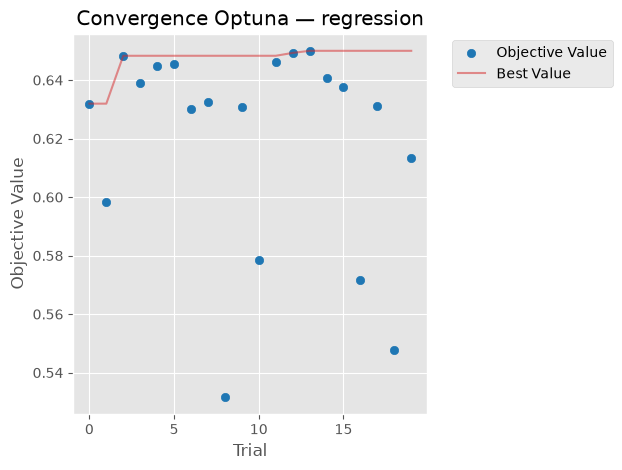

[I 2026-11-17 17:47:36,151] A new study created in memory with name: no-name-f7e21fcf-ac63-47f4-b5e5-e9b2e54e1daa


[I 2026-11-17 17:47:36,542] Trial 0 finished with value: 0.8854753031349526 and parameters: {'family': 'GradientBoosting', 'business_features': False, 'n_estimators': 50, 'min_samples_leaf': 2, 'gb_max_depth': 1, 'learning_rate': 0.146962368105409}. Best is trial 0 with value: 0.8854753031349526.


[I 2026-11-17 17:47:37,761] Trial 1 finished with value: 0.8765645917803957 and parameters: {'family': 'GradientBoosting', 'business_features': True, 'n_estimators': 200, 'min_samples_leaf': 3, 'gb_max_depth': 1, 'learning_rate': 0.03050945891610522}. Best is trial 0 with value: 0.8854753031349526.


[I 2026-11-17 17:47:38,899] Trial 2 finished with value: 0.8901109962630409 and parameters: {'family': 'GradientBoosting', 'business_features': False, 'n_estimators': 150, 'min_samples_leaf': 2, 'gb_max_depth': 2, 'learning_rate': 0.04649345697900868}. Best is trial 2 with value: 0.8901109962630409.


[I 2026-11-17 17:47:40,579] Trial 3 finished with value: 0.8836674412915851 and parameters: {'family': 'GradientBoosting', 'business_features': True, 'n_estimators': 150, 'min_samples_leaf': 1, 'gb_max_depth': 3, 'learning_rate': 0.029617890239950373}. Best is trial 2 with value: 0.8901109962630409.


[I 2026-11-17 17:47:41,576] Trial 4 finished with value: 0.8869738692661235 and parameters: {'family': 'GradientBoosting', 'business_features': False, 'n_estimators': 100, 'min_samples_leaf': 1, 'gb_max_depth': 3, 'learning_rate': 0.05510391929902154}. Best is trial 2 with value: 0.8901109962630409.


... (13 outputs left out)

[I 2026-11-17 17:48:00,495] Trial 18 finished with value: 0.887758390837309 and parameters: {'family': 'GradientBoosting', 'business_features': False, 'n_estimators': 100, 'min_samples_leaf': 6, 'gb_max_depth': 2, 'learning_rate': 0.03658735066896986}. Best is trial 14 with value: 0.8910301592098028.


[I 2026-11-17 17:48:01,621] Trial 19 finished with value: 0.8888344146638868 and parameters: {'family': 'GradientBoosting', 'business_features': False, 'n_estimators': 100, 'min_samples_leaf': 10, 'gb_max_depth': 2, 'learning_rate': 0.0923165602159225}. Best is trial 14 with value: 0.8910301592098028.


classification : meilleur essai = 0.891 +/- 0.016
Paramètres : {'family': 'GradientBoosting', 'business_features': False, 'n_estimators': 100, 'min_samples_leaf': 1, 'gb_max_depth': 2, 'learning_rate': 0.04231668749699029}
Retenu sur CV uniquement : Optuna GradientBoosting, variables métier=False


C:\Users\A127375\AppData\Local\Temp\ipykernel_37796\385482171.py:56: ExperimentalWarning: optuna.visualization.matplotlib._optimization_history.plot_optimization_history is experimental (supported from v2.2.0). The interface can change in the future.
  plot_optimization_history(study)


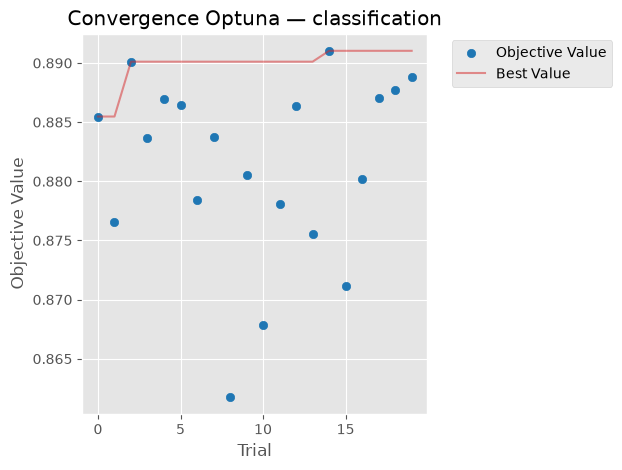

,defi,famille,variables_metier,etape,temps_fit_moyen_s,r2_moyenne,r2_ecart_type,mae_moyenne,mae_ecart_type,rmse_moyenne,rmse_ecart_type,roc_auc_moyenne,roc_auc_ecart_type,rappel_refus_moyenne,rappel_refus_ecart_type,f1_refus_moyenne,f1_refus_ecart_type
0,regression,Dummy,False,baseline,0.061,-0.002,0.002,50.464,2.894,63.301,3.445,NaN,NaN,NaN,NaN,NaN,NaN
1,regression,RandomForest,False,baseline,0.617,0.617,0.051,31.599,1.554,38.960,1.719,NaN,NaN,NaN,NaN,NaN,NaN
2,regression,RandomForest,True,baseline,0.438,0.612,0.058,31.709,1.723,39.157,1.717,NaN,NaN,NaN,NaN,NaN,NaN
3,regression,GradientBoosting,False,baseline,0.241,0.626,0.039,31.028,0.846,38.552,1.527,NaN,NaN,NaN,NaN,NaN,NaN
4,regression,GradientBoosting,True,baseline,0.207,0.625,0.050,30.954,1.214,38.526,1.630,NaN,NaN,NaN,NaN,NaN,NaN
5,classification,Dummy,False,baseline,0.014,NaN,NaN,NaN,NaN,NaN,NaN,0.500,0.000,1.000,0.000,0.768,0.002
6,classification,RandomForest,False,baseline,0.204,NaN,NaN,NaN,NaN,NaN,NaN,0.874,0.015,0.865,0.055,0.839,0.021
7,classification,RandomForest,True,baseline,0.177,NaN,NaN,NaN,NaN,NaN,NaN,0.872,0.016,0.851,0.032,0.828,0.007
8,classification,GradientBoosting,False,baseline,0.192,NaN,NaN,NaN,NaN,NaN,NaN,0.877,0.008,0.848,0.049,0.833,0.024
9,classification,GradientBoosting,True,baseline,0.211,NaN,NaN,NaN,NaN,NaN,NaN,0.871,0.011,0.850,0.042,0.832,0.014


Le maximum CV après tuning est optimiste ; il ne remplace pas le test final.


In [9]:
import optuna
from optuna.visualization.matplotlib import plot_optimization_history

N_TRIALS = 20
studies = {}
selected_pipelines = {}
selected_descriptions = {}

def objective(trial, task):
    family = trial.suggest_categorical('family', ['RandomForest', 'GradientBoosting'])
    features = trial.suggest_categorical('business_features', [False, True])
    parameters = {
        'n_estimators': trial.suggest_int('n_estimators', 50, 200, step=50),
        'min_samples_leaf': trial.suggest_int('min_samples_leaf', 1, 10),
    }
    if family == 'RandomForest':
        parameters['max_depth'] = trial.suggest_int('rf_max_depth', 3, 15)
    else:
        parameters['max_depth'] = trial.suggest_int('gb_max_depth', 1, 4)
        parameters['learning_rate'] = trial.suggest_float('learning_rate', 0.02, 0.2, log=True)
    candidate = clone(estimators[task][family]).set_params(**parameters)
    pipeline = build_scoring_pipeline(candidate, business_features=features)
    scores = cross_validate(
        pipeline, X_train, targets[task], cv=cv_splits,
        scoring=scorers[task], error_score='raise', n_jobs=1,
    )
    metric = primary_metrics[task]
    trial.set_user_attr('std', float(scores[f'test_{metric}'].std(ddof=0)))
    trial.set_user_attr('model_parameters', parameters)
    return float(scores[f'test_{metric}'].mean())

for task in targets:
    study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))
    study.optimize(lambda trial: objective(trial, task), n_trials=N_TRIALS)
    studies[task] = study
    best = study.best_trial
    tuned_estimator = clone(estimators[task][best.params['family']]).set_params(**best.user_attrs['model_parameters'])
    tuned_pipeline = build_scoring_pipeline(tuned_estimator, business_features=best.params['business_features'])
    scores = cross_validate(tuned_pipeline, X_train, targets[task], cv=cv_splits,
                            scoring=scorers[task], error_score='raise', n_jobs=1)
    record_cv(task, best.params['family'], best.params['business_features'], scores, 'optuna')
    metric = primary_metrics[task]
    baseline = cv_comparison.loc[
        cv_comparison['defi'].eq(task) & cv_comparison['famille'].ne('Dummy')
    ].sort_values(f'{metric}_moyenne', ascending=False).iloc[0]
    if best.value >= baseline[f'{metric}_moyenne']:
        selected_pipelines[task] = tuned_pipeline
        selected_descriptions[task] = f"Optuna {best.params['family']}, variables métier={best.params['business_features']}"
    else:
        base_model = clone(estimators[task][baseline['famille']])
        selected_pipelines[task] = build_scoring_pipeline(base_model, business_features=bool(baseline['variables_metier']))
        selected_descriptions[task] = f"Baseline {baseline['famille']}, variables métier={baseline['variables_metier']}"
    print(f'{task} : meilleur essai = {best.value:.3f} +/- {best.user_attrs["std"]:.3f}')
    print('Paramètres :', best.params)
    print('Retenu sur CV uniquement :', selected_descriptions[task])
    plot_optimization_history(study)
    plt.title(f'Convergence Optuna — {task}')
    plt.tight_layout()
    plt.show()

cv_comparison = pd.DataFrame(cv_rows)
display(cv_comparison.round(3))
print('Le maximum CV après tuning est optimiste ; il ne remplace pas le test final.')

## 7. Figer les choix et ouvrir le test final — 20 min

**Ne poursuivre que lorsque les modèles, hyperparamètres, variables et éventuel seuil sont figés.** Un seuil adapté aux refus doit être choisi avec des prédictions hors pli sur le train, jamais sur le test.

Réentraîner les deux pipelines retenus sur tout le train. Construire alors seulement `X_test = test_data.drop(columns=excluded_columns)` et les deux cibles test.

- Régression : R², MAE, RMSE, graphique prédit/réel et résidus.
- Classification : ROC-AUC sur `predict_proba` (colonne correspondant à la classe 1), F1 et rappel classe 0, matrice de confusion étiquetée `[0: refus, 1: accord]` et courbe ROC.
- Analyser les refus acceptés à tort et les accords refusés à tort, leurs coûts et les limites d'équité. Ne pas annoncer une conformité réglementaire sur la seule base de ces métriques.

Après consultation du test, ne pas relancer une boucle de tuning guidée par ses résultats.

,Test final
R²,0.647
MAE,28.929
RMSE,37.499
ROC-AUC,0.887
Rappel refus,0.867
F1 refus,0.855


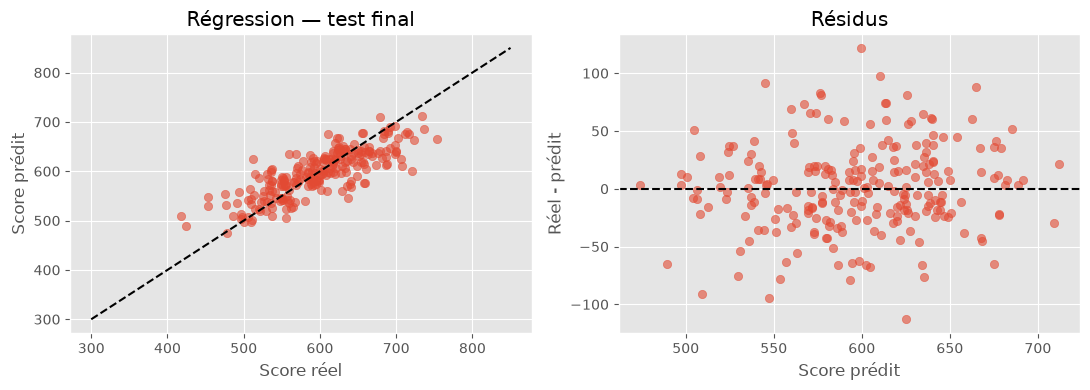

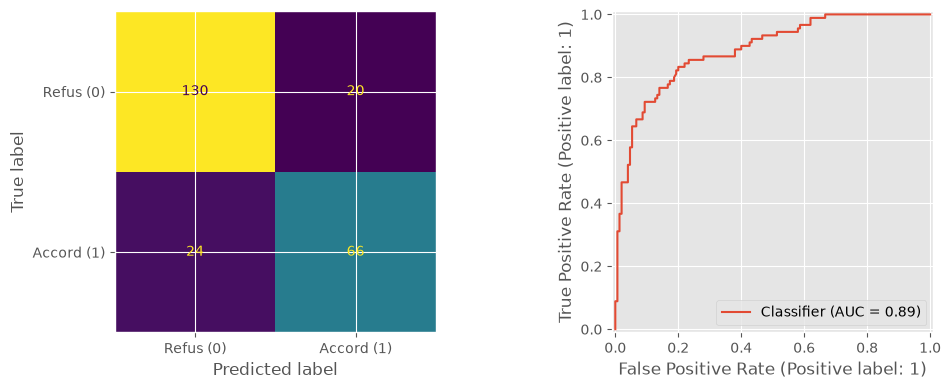

Refus historiques prédits comme accords : 20 / 150
Accords historiques prédits comme refus : 24 / 90
Seuil standard conservé ; aucun seuil ajusté sur le test. Ne plus tuner après cette évaluation.


In [10]:
from sklearn.metrics import (
    r2_score, mean_absolute_error, root_mean_squared_error, roc_auc_score,
    confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay,
)

X_test = test_data.drop(columns=excluded_columns).copy()
y_test_reg = test_data[TARGET_REG]
y_test_clf = test_data[TARGET_CLF]
best_regressor = selected_pipelines['regression'].fit(X_train, y_train_reg)
best_classifier = selected_pipelines['classification'].fit(X_train, y_train_clf)
reg_predictions = best_regressor.predict(X_test)
clf_predictions = best_classifier.predict(X_test)
positive_column = list(best_classifier.classes_).index(1)
probabilities = best_classifier.predict_proba(X_test)[:, positive_column]

test_metrics = pd.Series({
    'R²': r2_score(y_test_reg, reg_predictions),
    'MAE': mean_absolute_error(y_test_reg, reg_predictions),
    'RMSE': root_mean_squared_error(y_test_reg, reg_predictions),
    'ROC-AUC': roc_auc_score(y_test_clf, probabilities),
    'Rappel refus': recall_score(y_test_clf, clf_predictions, pos_label=0, zero_division=0),
    'F1 refus': f1_score(y_test_clf, clf_predictions, pos_label=0, zero_division=0),
}, name='Test final')
display(test_metrics.round(3).to_frame())

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(y_test_reg, reg_predictions, alpha=0.6)
axes[0].plot([300, 850], [300, 850], 'k--')
axes[0].set(xlabel='Score réel', ylabel='Score prédit', title='Régression — test final')
axes[1].scatter(reg_predictions, y_test_reg - reg_predictions, alpha=0.6)
axes[1].axhline(0, color='black', linestyle='--')
axes[1].set(xlabel='Score prédit', ylabel='Réel - prédit', title='Résidus')
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay.from_predictions(y_test_clf, clf_predictions, labels=[0, 1],
    display_labels=['Refus (0)', 'Accord (1)'], ax=axes[0], colorbar=False)
RocCurveDisplay.from_predictions(y_test_clf, probabilities, pos_label=1, ax=axes[1])
plt.tight_layout()
plt.show()
matrix = confusion_matrix(y_test_clf, clf_predictions, labels=[0, 1])
print(f'Refus historiques prédits comme accords : {matrix[0, 1]} / {matrix[0].sum()}')
print(f'Accords historiques prédits comme refus : {matrix[1, 0]} / {matrix[1].sum()}')
print('Seuil standard conservé ; aucun seuil ajusté sur le test. Ne plus tuner après cette évaluation.')

## 8. Exporter, tester et synthétiser — 25 min

### Livrables à produire

- [x] Notebook exécuté dans l'ordre, avec constats, tableau comparatif, convergence Optuna et matrice de confusion.
- [x] `models/best_regressor_pipeline.joblib` et `models/best_classifier_pipeline.joblib` : **pipelines complets**, pas seulement les estimateurs.
- [x] Tests Pytest : rechargement dans un processus neuf, dimensions de sortie, catégories inconnues et valeurs manquantes.
- [x] [Fiche de synthèse imprimable](synthese_scoring_ml.html) : scores CV moyenne +/- écart-type, scores test, compromis métier et limites. Les paramètres détaillés sont affichés dans la section Optuna.

Vérifier que les prédictions avant/après rechargement sont identiques. Ne pas remplacer `credit_linear_model.joblib` ni changer le contrat de l'API existante : l'intégration applicative est une étape distincte.

**Lecture des résultats :** l'ajout de variables métier n'améliore pas systématiquement les modèles. La comparaison et Optuna peuvent retenir la variante sans variables dérivées ; ce choix est fait avant l'ouverture du test, uniquement sur les scores CV.

In [11]:
import html
import joblib
import subprocess
from IPython.display import Markdown

MODELS_DIR.mkdir(exist_ok=True)
model_paths = {
    'regression': MODELS_DIR / 'best_regressor_pipeline.joblib',
    'classification': MODELS_DIR / 'best_classifier_pipeline.joblib',
}
for task, model in [('regression', best_regressor), ('classification', best_classifier)]:
    joblib.dump(model, model_paths[task])
    loaded = joblib.load(model_paths[task])
    np.testing.assert_allclose(loaded.predict(X_test), model.predict(X_test))
    probe = X_train.iloc[:3].copy()
    for column in probe.select_dtypes(exclude='number').columns:
        probe[column] = 'CATEGORIE_INCONNUE'
    probe.loc[probe.index[0], 'revenu_mensuel'] = np.nan
    assert loaded.predict(probe).shape == (3,)
    assert np.isfinite(loaded.predict(probe)).all()
    if task == 'classification':
        assert loaded.predict_proba(probe).shape == (3, 2)

completed = subprocess.run(
    [sys.executable, '-m', 'pytest', str(PROJECT_ROOT / 'tests' / 'test_credit_training.py'), '-q'],
    cwd=PROJECT_ROOT, capture_output=True, text=True,
)
print(completed.stdout)
if completed.returncode:
    raise RuntimeError(completed.stdout + completed.stderr)

summary_lines = [
    '# Synthèse — Optimisation du scoring IA-TOS',
    f'Protocole : {len(X_train)} dossiers train, {len(X_test)} test ; cinq plis stratifiés sur la décision ; graine {RANDOM_STATE}.',
    f'Données train : {int(train_data.isna().sum().sum())} valeurs manquantes ; refus : {y_train_clf.eq(0).mean():.1%}. Aucune ligne supprimée.',
    'Variables métier : reste à vivre hors intérêts et ratio épargne/emprunt ; exclusion des deux cibles, de l’identifiant et des attributs socio-démographiques listés au départ.',
    f'Régression retenue : {selected_descriptions["regression"]}.',
    f'Classification retenue : {selected_descriptions["classification"]}.',
    f'Budget Optuna : {N_TRIALS} essais par défi, sélection exclusivement sur CV.',
    f'Test final : erreur absolue moyenne {test_metrics["MAE"]:.1f} points ; rappel des refus {test_metrics["Rappel refus"]:.1%}.',
    f'Compromis : {matrix[0, 1]} refus historiques acceptés à tort et {matrix[1, 0]} accords refusés à tort. Les coûts ne sont pas chiffrés sans hypothèses métier.',
    'Limites : petit dataset synthétique, sélection CV optimiste après essais multiples, absence de validation temporelle/externe. Les décisions historiques ne mesurent pas directement les défauts de paiement.',
    'Équité : exclure des attributs ne supprime pas les biais ou les proxys. Une analyse par groupes et une validation réglementaire restent nécessaires avant tout usage réel.',
]
display(Markdown('\n\n'.join(summary_lines)))
compact_rows = []
for row in cv_rows:
    compact = {key: row[key] for key in ('defi', 'famille', 'variables_metier', 'etape')}
    for metric in scorers[row['defi']]:
        compact[metric] = f"{row[f'{metric}_moyenne']:.3f} +/- {row[f'{metric}_ecart_type']:.3f}"
    compact_rows.append(compact)
summary_path = PROJECT_ROOT / 'notebooks' / 'synthese_scoring_ml.html'
summary_html = '<!doctype html><html lang="fr"><meta charset="utf-8"><title>Synthèse scoring ML</title>'
summary_html += '<style>body{font:11px Arial;max-width:1000px;margin:20px auto}table{border-collapse:collapse;font-size:10px}td,th{padding:3px;border:1px solid #ccc}@page{size:A4;margin:12mm}h1{font-size:18px}</style>'
summary_html += ''.join(f'<p>{html.escape(line)}</p>' for line in summary_lines)
summary_html += pd.DataFrame(compact_rows).fillna('—').to_html(index=False)
summary_html += '<h2>Test final</h2>' + test_metrics.round(3).to_frame().T.to_html(index=False)
summary_html += '</html>'
summary_path.write_text(summary_html, encoding='utf-8')
print('Synthèse imprimable :', summary_path)
print('Pipelines exportés :', *model_paths.values(), sep='\n')

...                                                                      [100%]
3 passed in 12.26s



# Synthèse — Optimisation du scoring IA-TOS

Protocole : 960 dossiers train, 240 test ; cinq plis stratifiés sur la décision ; graine 42.

Données train : 0 valeurs manquantes ; refus : 62.3%. Aucune ligne supprimée.

Variables métier : reste à vivre hors intérêts et ratio épargne/emprunt ; exclusion des deux cibles, de l’identifiant et des attributs socio-démographiques listés au départ.

Régression retenue : Optuna GradientBoosting, variables métier=False.

Classification retenue : Optuna GradientBoosting, variables métier=False.

Budget Optuna : 20 essais par défi, sélection exclusivement sur CV.

Test final : erreur absolue moyenne 28.9 points ; rappel des refus 86.7%.

Compromis : 20 refus historiques acceptés à tort et 24 accords refusés à tort. Les coûts ne sont pas chiffrés sans hypothèses métier.

Limites : petit dataset synthétique, sélection CV optimiste après essais multiples, absence de validation temporelle/externe. Les décisions historiques ne mesurent pas directement les défauts de paiement.

Équité : exclure des attributs ne supprime pas les biais ou les proxys. Une analyse par groupes et une validation réglementaire restent nécessaires avant tout usage réel.

Synthèse imprimable : C:\GIT\formation-AI\2026-ATLAS-Brief-M0B1\notebooks\synthese_scoring_ml.html
Pipelines exportés :
C:\GIT\formation-AI\2026-ATLAS-Brief-M0B1\models\best_regressor_pipeline.joblib
C:\GIT\formation-AI\2026-ATLAS-Brief-M0B1\models\best_classifier_pipeline.joblib
